# Credit Card Fraud Detection - EDA and Modelling
**Dataset:** [Kaggle - Credit Card Fraud Detection (ULB)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) - 284,807 European card transactions over two days, 492 frauds (0.17%).

**Why this problem is interesting:** with 99.8% legitimate transactions, a model that always predicts "legit" scores 99.8% accuracy and catches zero fraud. So this notebook uses **PR-AUC**, a **chronological split** and a **cost-based decision threshold** instead of accuracy.

Contents: 1) Data checks · 2) EDA · 3) Split · 4) Models · 5) Threshold tuning · 6) Explainability · 7) Takeaways

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import joblib, json
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, confusion_matrix
from common import load_data, add_features, time_split, FEATURES, DATA_PATH, MODEL_DIR, ROOT
sns.set_theme(style="whitegrid")
raw = pd.read_csv(DATA_PATH)
raw.shape

(284807, 31)

## 1. Data checks

In [2]:
print("Missing values:", int(raw.isna().sum().sum()))
print("Exact duplicate rows:", int(raw.duplicated().sum()))
print("Class balance:"); print(raw.Class.value_counts().to_frame("count").assign(pct=lambda d: (100*d["count"]/d["count"].sum()).round(3)))

Missing values: 0


Exact duplicate rows: 1081
Class balance:
        count     pct
Class                
0      284315  99.827
1         492   0.173


**Findings:** no missing values, but **1,081 exact duplicate rows**. Duplicates would leak between train and test, so the pipeline drops them (283,726 rows, 473 frauds remain). Features `V1`-`V28` are anonymised PCA components; only `Time` and `Amount` are interpretable.

## 2. EDA

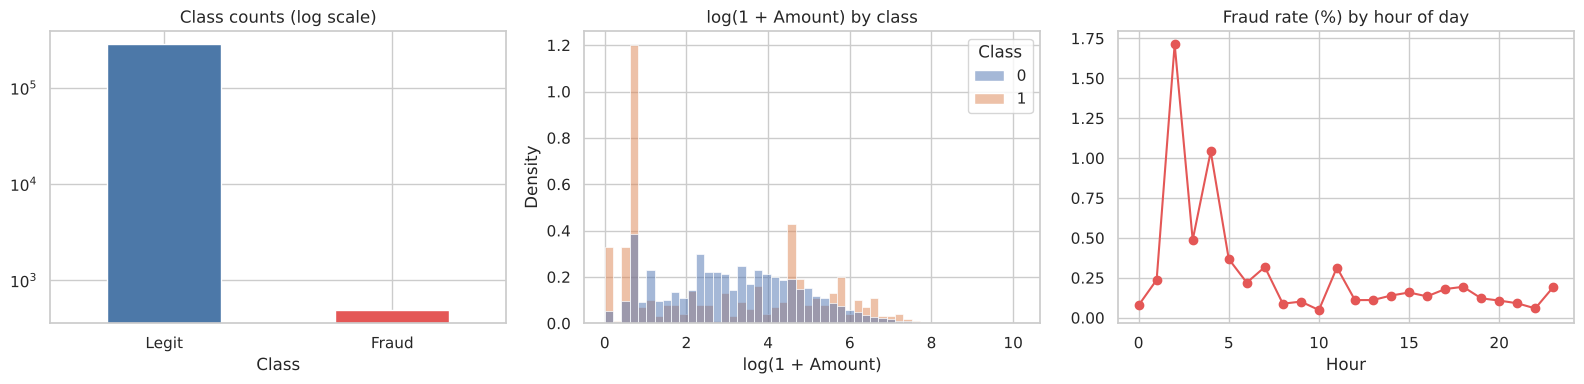

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
raw.Class.value_counts().plot.bar(ax=axes[0], color=["#4C78A8", "#E45756"], logy=True)
axes[0].set_title("Class counts (log scale)"); axes[0].set_xticklabels(["Legit", "Fraud"], rotation=0)
sns.histplot(data=raw, x=np.log1p(raw.Amount), hue="Class", stat="density", common_norm=False, bins=50, ax=axes[1])
axes[1].set_title("log(1 + Amount) by class"); axes[1].set_xlabel("log(1 + Amount)")
h = (raw.Time // 3600) % 24
rate = raw.groupby(h).Class.mean() * 100
rate.plot(ax=axes[2], marker="o", color="#E45756"); axes[2].set_title("Fraud rate (%) by hour of day"); axes[2].set_xlabel("Hour")
plt.tight_layout(); plt.show()

In [4]:
print(raw.groupby("Class").Amount.describe().round(2))

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87


**Findings**
- Fraud is *extremely* rare, so resampling/weighting and PR-based metrics are needed.
- Frauds skew to **smaller amounts** (median 9.25 vs 22.00) - many look like small "card testing" charges, so amount alone is not a reliable signal.
- Fraud rate varies with hour of day: **0.52% between hours 0-6 vs 0.14% afterwards** (peak 1.7% at hour 2). Caveat: `Time` is seconds since the *first* transaction, so "hour" assumes the data starts near midnight (volume dips in hours 1-5, which supports that, but it is an assumption). With only two days of data this is a hint, not a proven pattern - and in the final model `hour` did not rank among the top-15 SHAP features; the PCA components carry most of the signal.

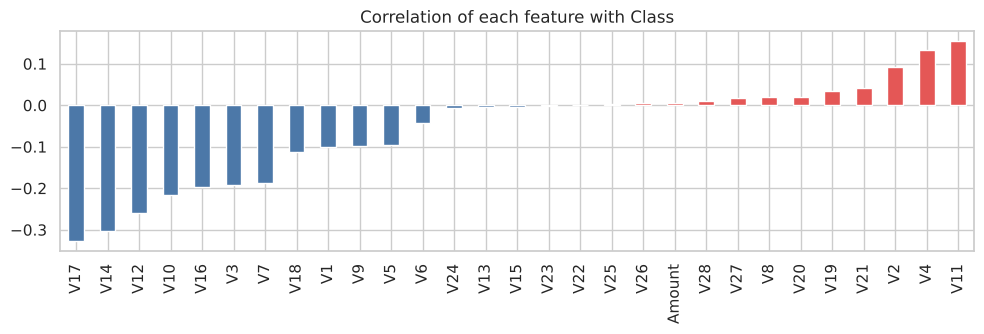

V17    0.326
V14    0.303
V12    0.261
V10    0.217
V16    0.197
V3     0.193
Name: Class, dtype: float64

In [5]:
corr = raw.drop(columns=["Time"]).corr()["Class"].drop("Class").sort_values()
fig, ax = plt.subplots(figsize=(10, 3.5))
corr.plot.bar(ax=ax, color=np.where(corr < 0, "#4C78A8", "#E45756")); ax.set_title("Correlation of each feature with Class")
plt.tight_layout(); plt.show()
corr.abs().sort_values(ascending=False).head(6).round(3)

## 3. Chronological split
A random split lets the model peek at the future (fraud patterns drift). Instead: first 60% of time = train, next 20% = validation (model selection + threshold), last 20% = **test** (touched once).

In [6]:
df = add_features(load_data())
train, val, test = time_split(df)
pd.DataFrame({"rows": [len(train), len(val), len(test)],
              "frauds": [int(train.Class.sum()), int(val.Class.sum()), int(test.Class.sum())]},
             index=["train", "validation", "test"]).assign(fraud_pct=lambda d: (100*d.frauds/d.rows).round(3))

,rows,frauds,fraud_pct
train,170235,342,0.201
validation,56745,57,0.100
test,56746,74,0.130


**Caveat:** the validation and test sets contain only 57 and 74 frauds, so metrics have wide uncertainty - differences of 1-2 points of PR-AUC between models are within noise.

## 4. Model comparison

In [7]:
results = json.load(open(ROOT / "reports" / "metrics.json"))
cmp = pd.DataFrame(results["model_comparison"]).T
cmp.columns = ["Val PR-AUC", "Val ROC-AUC", "Test PR-AUC", "Test ROC-AUC"]
display(cmp)
print("Selected on validation PR-AUC ->", results["selected_model"])

,Val PR-AUC,Val ROC-AUC,Test PR-AUC,Test ROC-AUC
Logistic Regression,0.7600,0.9719,0.7460,0.9832
Random Forest,0.7797,0.9660,0.8159,0.9516
XGBoost (class weights),0.7734,0.9792,0.7849,0.9784
XGBoost + SMOTE,0.7730,0.9683,0.7787,0.9710


Selected on validation PR-AUC -> Random Forest


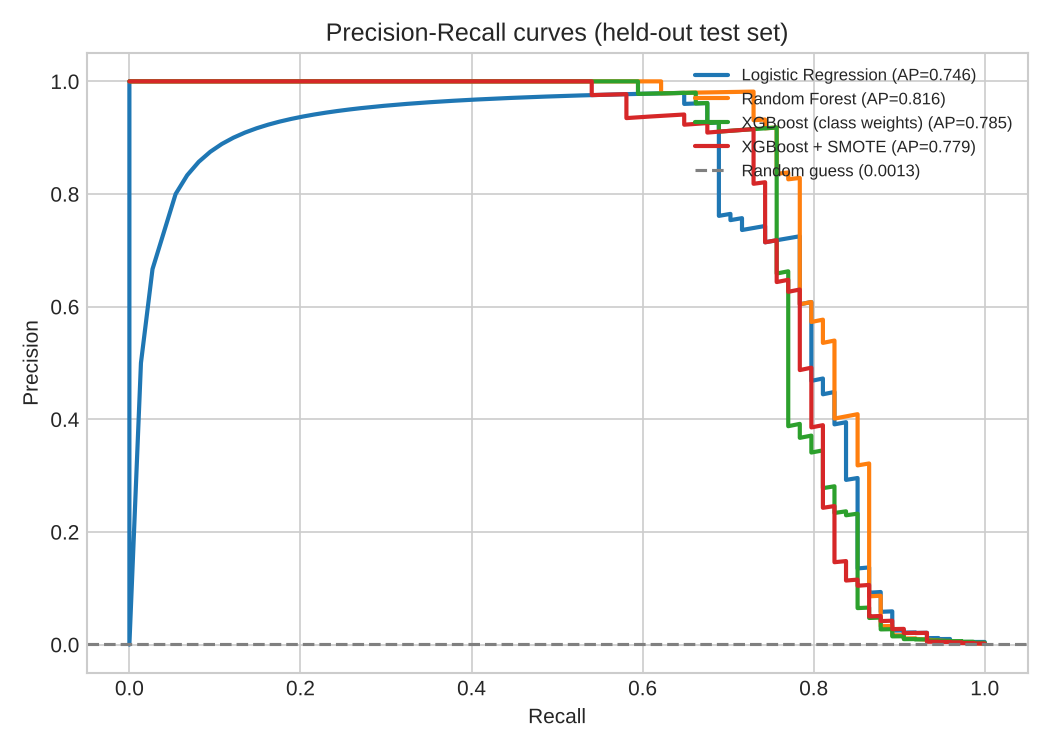

In [8]:
from IPython.display import Image
Image(filename=str(ROOT / "reports" / "figures" / "pr_curves.png"))

Models compared (all trained in `src/train.py`): Logistic Regression (class-weighted), Random Forest (balanced subsample), XGBoost (class weights) and XGBoost + SMOTE. ROC-AUC looks great for every model (0.95+) which is exactly why it is misleading here - PR-AUC separates them far better.

**SMOTE lesson:** my first feature set included an `is_round_amount` flag. SHAP showed the SMOTE-trained model had learned "round amount => legit", because SMOTE *interpolates* between fraud rows and so synthetic frauds never have round amounts. I removed the discrete flags: SMOTE and binary/discrete features do not mix.

## 5. Threshold tuning by business cost

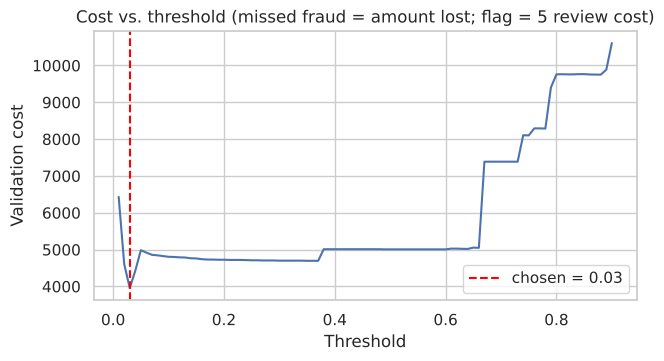

In [9]:
bundle = joblib.load(MODEL_DIR / "fraud_model.joblib")
model, thr = bundle["model"], bundle["threshold"]
p_test = model.predict_proba(test[FEATURES])[:, 1]
p_val = model.predict_proba(val[FEATURES])[:, 1]

REVIEW_COST = 5.0
def cost(y, p, amt, t):
    flagged = p >= t
    return amt[(~flagged) & (y == 1)].sum() + REVIEW_COST * flagged.sum()

grid = np.linspace(0.01, 0.9, 90)
costs = [cost(val.Class.values, p_val, val.Amount.values, t) for t in grid]
plt.figure(figsize=(7, 3.5)); plt.plot(grid, costs); plt.axvline(thr, color="red", ls="--", label=f"chosen = {thr:.2f}")
plt.xlabel("Threshold"); plt.ylabel("Validation cost"); plt.title("Cost vs. threshold (missed fraud = amount lost; flag = 5 review cost)"); plt.legend(); plt.show()

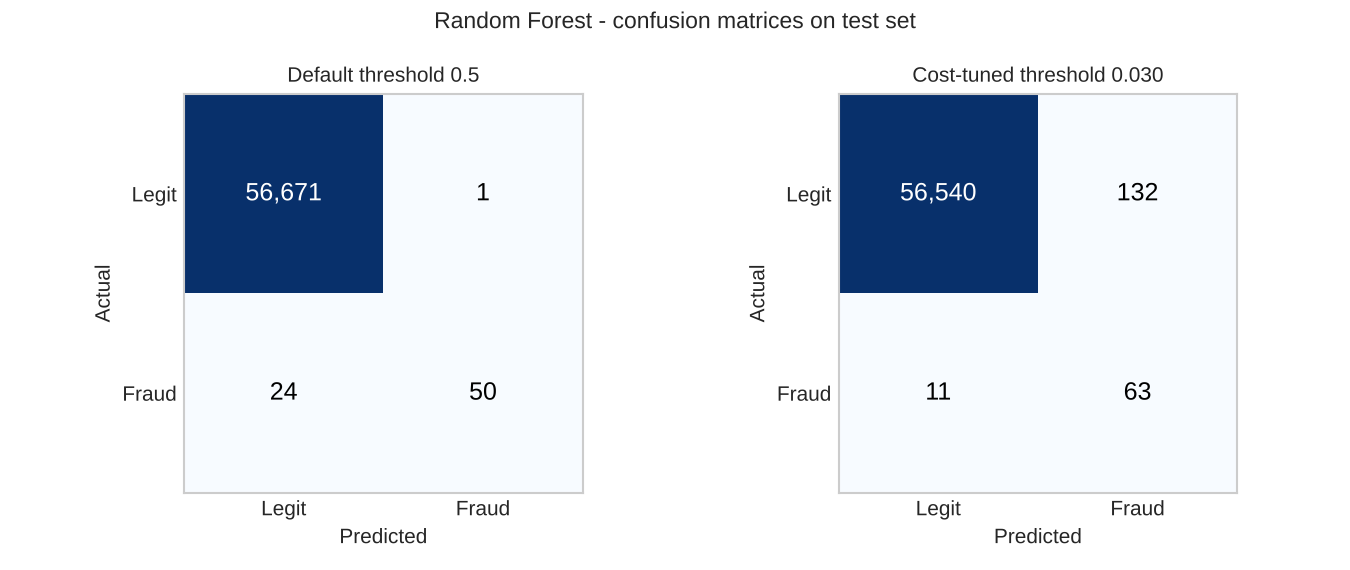

In [10]:
Image(filename=str(ROOT / "reports" / "figures" / "confusion_matrices.png"))

In [11]:
pd.DataFrame({"default 0.5": results["test_at_default_0.5"], "tuned": results["test_at_tuned_threshold"]}).T

,threshold,precision,recall,tp,fp,fn,tn
default 0.5,0.50,0.9804,0.6757,50.0,1.0,24.0,56671.0
tuned,0.03,0.3231,0.8514,63.0,132.0,11.0,56540.0


In [12]:
print(json.dumps(results["test_cost"], indent=2))

{
  "no_model_loss": 7727.67,
  "default_threshold": 4196.59,
  "tuned_threshold": 3337.2,
  "savings_vs_no_model_pct": 56.8
}


**Reading the trade-off:** at the default 0.5 threshold the model is very precise (about 98%) but misses about a third of frauds. Lowering the threshold to the cost-optimal value catches about 85% of frauds at the price of more false alarms. Which is "better" depends entirely on the cost assumptions - the review cost of 5 is an assumption, not a fact from the dataset.

## 6. Explainability (SHAP)

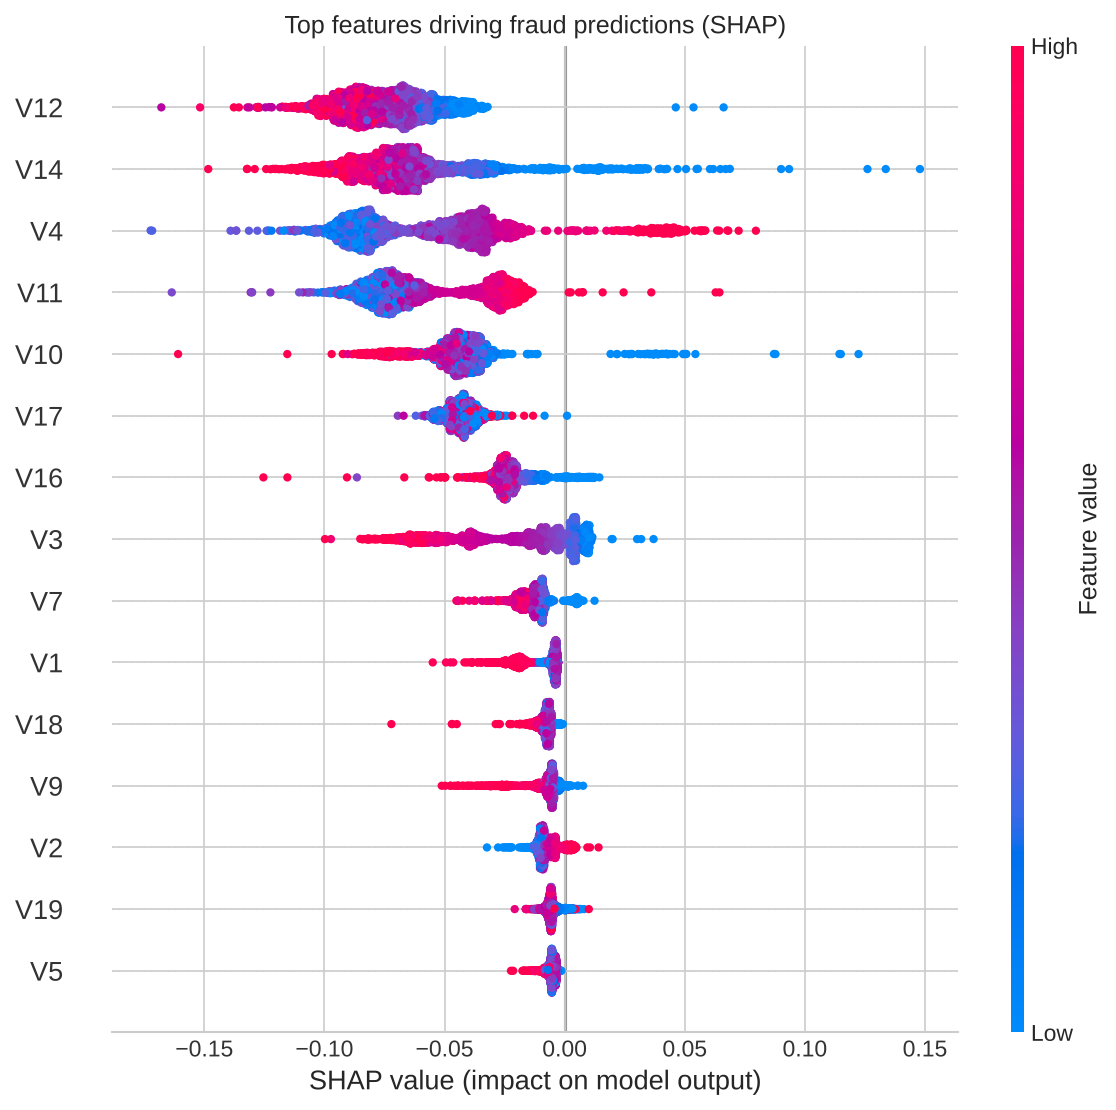

In [13]:
Image(filename=str(ROOT / "reports" / "figures" / "shap_summary.png"))

`V12`, `V14`, `V4`, `V11` and `V10` dominate the final model. Low `V14` and low `V12` values push predictions toward fraud, high `V4` and high `V11` do too. The V-features are anonymised, so we cannot say what they mean in business terms - only that the model relies on them.

## 7. Takeaways
1. Dropped **1,081 duplicate rows** and used a **time-based split** to avoid leakage.
2. Tree models beat logistic regression on PR-AUC (~0.78-0.82 vs ~0.75 on test); differences *between* tree models are within noise given only 74 test frauds.
3. **Threshold choice matters more than model choice**: moving from 0.5 to a cost-tuned threshold lifted recall from about 68% to about 85%.
4. Found and fixed a **SMOTE artefact** (spurious "round amount" rule) via SHAP.
5. Limitations: 2 days of data, anonymised features, assumed cost model, no concept-drift monitoring.